### Data Preparation 

We use Dataset of Real Waste [Link](https://archive.ics.uci.edu/dataset/908/realwaste)

In [38]:
# setup the realwaste_data.csv for the custom dataset class
# saved path : in data/realwaste_data.csv
from pathlib import Path
import pandas as pd
from PIL import Image
from sklearn.model_selection import train_test_split
from torch.utils.data import Dataset
from torch import optim

ROOT = Path("../data/RealWasteData/realwaste-main/RealWaste")
OUT  = Path("../data/realwaste_data.csv")

classes = sorted(d.name for d in ROOT.iterdir() if d.is_dir())
class_to_idx = {c: i for i, c in enumerate(classes)}

rows, bad = [], []
for c in classes:
    for p in sorted((ROOT / c).glob("*.jpg")):
        try:
            with Image.open(p) as im:
                im.verify()                      # catch truncated/corrupt files now
                w, h = im.size
        except Exception as e:
            bad.append((p, e)); continue
        rows.append({
            "filepath": p.relative_to(ROOT).as_posix(),   # "Paper/Paper_1.jpg"
            "class_name": c,
            "label": class_to_idx[c],
            "width": w, "height": h,
        })

df = pd.DataFrame(rows)
df.to_csv(OUT, index=False)
print(f"{len(df)} images, {len(bad)} unreadable -> {OUT}")



4752 images, 0 unreadable -> ../data/realwaste_data.csv


In [39]:
# custom data set
import os
import pandas as pd
from torchvision.io import decode_image

class RealWasteDataset(Dataset):
    """
    custom datset.
        data_file - data/realwaste_data.csv
        image_path -  data/RealWasteData/realwaste-main/RealWaste
    """
    def __init__(self, data_file, image_path, transform=None):
        self.image_path = Path(image_path)
        self.image_lables = pd.read_csv(data_file)
        self.transform = transform

        # label -> class name mapping, taken from the manifest
        pairs = self.image_lables[["label", "class_name"]].drop_duplicates().sort_values("label")
        self.classes = pairs.class_name.tolist()
        self.class_to_idx = dict(zip(pairs.class_name, pairs.label))

    def __len__(self):
        return len(self.image_lables)

    def __getitem__(self, index):
        row = self.image_lables.iloc[index]
        image = Image.open(self.image_path / row.filepath).convert("RGB")
        if self.transform is not None:
            image = self.transform(image)
        return image, int(row.label)

    @property
    def targets(self):
        """All labels in manifest order, for stratifying the split."""
        return self.image_lables.label.tolist()


In [40]:
# test the class
ds = RealWasteDataset(
    "../data/realwaste_data.csv",
    "../data/RealWasteData/realwaste-main/RealWaste",
)

image, label = ds[3000]
print(len(ds), image.size, image.mode, label)


4752 (524, 524) RGB 5


In [41]:
from pathlib import Path
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Subset
from torchvision import transforms


manifest = "../data/realwaste_data.csv"
dataset_root = "../data/RealWasteData/realwaste-main/RealWaste"

base = RealWasteDataset(manifest, dataset_root)
# targets 
y = base.targets


# transfrom to 64*64
train_tf = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

# transfrom without augemntation to 64*64
eval_tf = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

# train test split 
idx_train, idx_temp = train_test_split(
    range(len(y)), test_size = 0.3, stratify=y, random_state=42
)

y_temp = [y[i] for i in idx_temp]

idx_val, idx_test = train_test_split(
    idx_temp, test_size=0.50, stratify=y_temp, random_state=42
)


# Dataset - train with augmentation, val/test without 
train_ds = Subset(RealWasteDataset(manifest, dataset_root, transform=train_tf), idx_train)
val_ds = Subset(RealWasteDataset(manifest, dataset_root, transform=eval_tf), idx_val)
test_ds = Subset(RealWasteDataset(manifest, dataset_root, transform=eval_tf), idx_test)
print(f"Traing size : {len(train_ds)}")
print(f"validation size : {len(val_ds)}")
print(f"tast size {len(test_ds)}")

# dataloder 
train_loader = DataLoader(train_ds, batch_size=64, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=64, shuffle=False)
test_loader = DataLoader(test_ds, batch_size=64, shuffle=False)

# len(train_loader)
# len(val_loader)
# len(test_loader)


Traing size : 3326
validation size : 713
tast size 713


Feature batch shape: torch.Size([64, 3, 64, 64])
Labels batch shape: torch.Size([64])


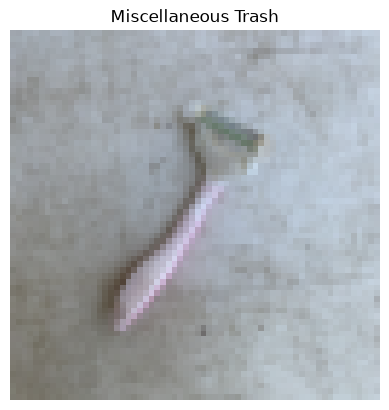

In [42]:
import matplotlib.pyplot as plt
import torch

mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std  = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

train_features, train_labels = next(iter(train_loader))
print(f"Feature batch shape: {train_features.size()}")   # [64, 3, 64, 64]
print(f"Labels batch shape: {train_labels.size()}")      # [64]

img = train_features[0] * std + mean        # undo Normalize
img = img.clamp(0, 1).permute(1, 2, 0)      # [3,64,64] -> [64,64,3]

plt.imshow(img)
plt.axis("off")
plt.title(base.classes[train_labels[0]])
plt.show()


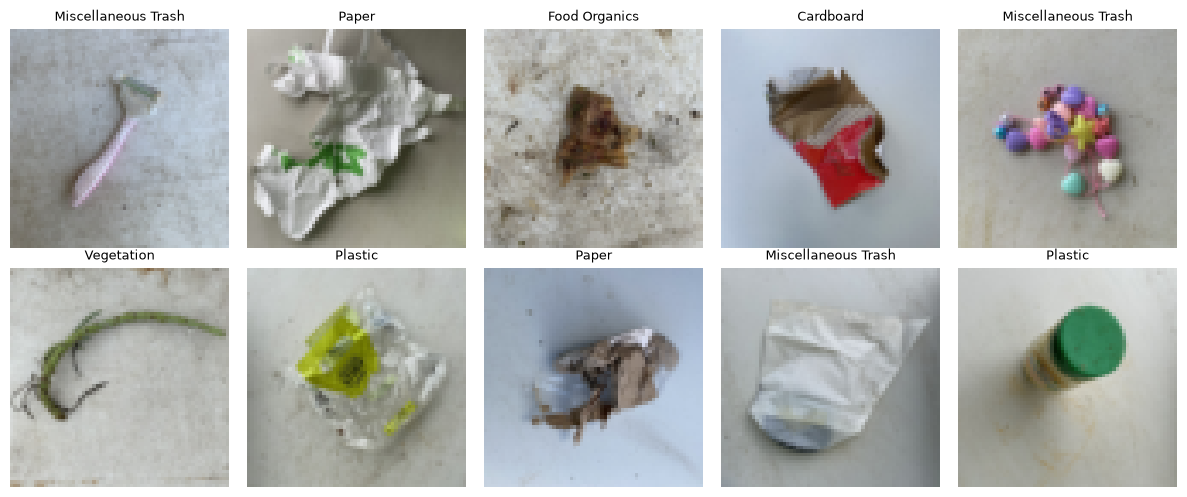

In [43]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for ax, img, lab in zip(axes.flat, train_features, train_labels):
    ax.imshow((img * std + mean).clamp(0, 1).permute(1, 2, 0))
    ax.set_title(base.classes[lab], fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()


## CNN
Building the CNN
1. Standard CNN
2. Light Weight CNN

In [44]:
# standard CNN
import torch.nn as nn

class WasteImageNN(nn.Module):

    def __init__(self):
        super().__init__()
        # features extraction 
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2), # --> 32*32*32

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),  # --> 64*16*16

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(inplace=True), 
            nn.MaxPool2d(2), # --> 128*8*8

            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2) , # 256*4*4
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.5),
            nn.Linear(4096, 256),
            nn.ReLU(inplace=True),
            nn.Dropout(0.5),
            nn.Linear(256, 9)
        )

    def forward(self,x):
        return self.classifier(self.features(x))


In [45]:
# create the Nural Network Model

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using {device} device")

Using cuda device


In [46]:
model = WasteImageNN().to(device)
print(model)
total_params = sum(p.numel() for p in model.parameters())
print(f"Total parameters: {total_params:,}")

WasteImageNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU(inplace=True)
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU(inplace=True)
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (9): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (10): ReLU(inplace=True)
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Dropout(p=0.5, inplace=False)
    (2): Linear(in_features=4096, out_features=256, bias=True)
    (3): ReLU(inplace=True)
    

## Train for 20 epochs

In [47]:
def train(model, train_loader, val_loader, num_ephohs, lr):
    """
    Train model and track loss

    Args:

        model : Pytorch model
        train_loader : Training Data loader
        num_epohs : # of Epochs
        lr : learning rate

    returns:

        training losses: list of traing losses per epoch
    """
    # check the gpu
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    print(f"Using the device : {device}\n")

    # move the model to device
    model = model.to(device)

    # loss and optimizer
    cirterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)

    train_loss = []
    validation_loss = []

    print(f"Training for {num_ephohs} epoches...\n")

    for epoch in range(num_ephohs):
        # ============================= Training =============================
        model.train()
        epoch_loss = 0

        for batch_x, batch_y in train_loader:
            # move batch to the device 
            batch_x, batch_y = batch_x.to(device), batch_y.to(device)

            # zero gradients 
            optimizer.zero_grad()

            # forward pass 
            outputs = model(batch_x)
            loss = cirterion(outputs, batch_y)

            # backpropagation
            loss.backward()

            # update weights 
            optimizer.step()

            epoch_loss += loss.item()

        # avarage training loss 
        avg_loss = epoch_loss/len(train_loader)
        train_loss.append(avg_loss)

        # ============================= Validation =============================
        model.eval()
        valid_loss = 0

        with torch.no_grad():
            for batch_x, batch_y in val_loader:
                batch_x, batch_y = batch_x.to(device), batch_y.to(device)
                outputs = model(batch_x)
                loss = cirterion(outputs, batch_y)
                valid_loss += loss.item()

        avg_valid_loss = valid_loss/len(val_loader)
        validation_loss.append(avg_valid_loss)


        print(f"Epoch [{epoch+1}/{num_ephohs}] | Train Loss: {avg_loss:.4f} |  Validation Loss : {avg_valid_loss:.4f}")

    print("\nTrain is Completed !")
    return train_loss, validation_loss

In [48]:
len(train_loader)

52

In [49]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score
)
import numpy as np
## Helper functions
def plot_training_loss(train_losses, validation_losses):
    """Plot training loss."""

    plt.figure(figsize=(10, 5))

    epochs = range(1, len(train_losses)+1)
    plt.plot(epochs,train_losses, marker='o', label="Train_loss")
    plt.plot(epochs,validation_losses, marker='s', label="Validation loss")

    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.title('Training Loss')
    plt.grid(True, alpha=0.3)
    plt.show()

def plot_cm_marices(cm, class_names=None):
    if class_names is None:
        class_names = [str(i) for i in range(cm.shape[0])]

    # row-normalize: each row sums to 100% -> diagonal is per-class recall
    row_sums = cm.sum(axis=1, keepdims=True)
    cm_norm = 100 * cm / row_sums.clip(min=1)

    fig, axes = plt.subplots(1, 2, figsize=(18, 7))
    panels = [
        (cm, "Confusion Matrix (counts)", "d"),
        (cm_norm, "Confusion Matrix (% of true class)", ".1f"),
    ]

    for ax, (matrix, title, fmt) in zip(axes, panels):
        im = ax.imshow(matrix, cmap="Blues")
        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

        ax.set_xticks(range(len(class_names)))
        ax.set_yticks(range(len(class_names)))
        ax.set_xticklabels(class_names, rotation=45, ha="right")
        ax.set_yticklabels(class_names)
        ax.set_xlabel("Predicted label")
        ax.set_ylabel("True label")
        ax.set_title(title)

        # write the value in each cell, white text on dark cells
        threshold = matrix.max() / 2
        for i in range(matrix.shape[0]):
            for j in range(matrix.shape[1]):
                ax.text(j, i, format(matrix[i, j], fmt),
                        ha="center", va="center", fontsize=9,
                        color="white" if matrix[i, j] > threshold else "black")

    plt.tight_layout()
    plt.show()

# evaluvate test 
def evaluate_test(model, test_loader):
    """Evaluate model on test set."""
    # Check for GPU
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    model = model.to(device)

    model.eval()
    correct = 0
    total = 0

    all_predictions = []
    all_labels = []

    with torch.no_grad():
        for batch_x, batch_y in test_loader:
            # Move data to device
            batch_x, batch_y = batch_x.to(device), batch_y.to(device)

            outputs = model(batch_x)
            _, predicted = torch.max(outputs, 1)
            all_predictions.extend(predicted.cpu().numpy())
            all_labels.extend(batch_y.cpu().numpy())
            total += batch_y.size(0)
            correct += (predicted == batch_y).sum().item()

    # Accuracy 
    test_accuracy = 100 * correct / total
    print(f"\n{'='*50}")
    print(f"TEST ACCURACY: {test_accuracy:.4f}%")
    print(f"{'='*50}")

    # confusion matrix 
    cm = confusion_matrix(all_labels, all_predictions)
    print(f"\n{'='*50}")
    print(f"CM : {cm}")
    print(f"{'='*50}")
    # test_loader.dataset is a Subset -> .dataset is the RealWasteDataset
    plot_cm_marices(cm, class_names=test_loader.dataset.dataset.classes)

    # Overall Precision
    precision = precision_score(
        all_labels,
        all_predictions,
        average="weighted"
    )
    print(f"\n{'='*50}")
    print(f"Precision: {precision:.4f}%")
    print(f"{'='*50}")
    
    # Overall Recall
    recall = recall_score(
        all_labels,
        all_predictions,
        average="weighted"
    )
    print(f"\n{'='*50}")
    print(f"Recall: {recall:.4f}%")
    print(f"{'='*50}")

    return test_accuracy, cm, precision, recall

Using the device : cuda

Training for 20 epoches...

Epoch [1/20] | Train Loss: 2.1106 |  Validation Loss : 2.0007
Epoch [2/20] | Train Loss: 1.8123 |  Validation Loss : 1.5874
Epoch [3/20] | Train Loss: 1.5540 |  Validation Loss : 1.5173
Epoch [4/20] | Train Loss: 1.4564 |  Validation Loss : 1.3278
Epoch [5/20] | Train Loss: 1.3351 |  Validation Loss : 1.2080
Epoch [6/20] | Train Loss: 1.2593 |  Validation Loss : 1.1971
Epoch [7/20] | Train Loss: 1.1829 |  Validation Loss : 1.1670
Epoch [8/20] | Train Loss: 1.1414 |  Validation Loss : 1.0944
Epoch [9/20] | Train Loss: 1.0766 |  Validation Loss : 1.0815
Epoch [10/20] | Train Loss: 1.0348 |  Validation Loss : 0.9857
Epoch [11/20] | Train Loss: 1.0323 |  Validation Loss : 1.0548
Epoch [12/20] | Train Loss: 0.9678 |  Validation Loss : 0.9726
Epoch [13/20] | Train Loss: 0.9109 |  Validation Loss : 0.8879
Epoch [14/20] | Train Loss: 0.8872 |  Validation Loss : 0.9605
Epoch [15/20] | Train Loss: 0.8639 |  Validation Loss : 0.8831
Epoch [16/2

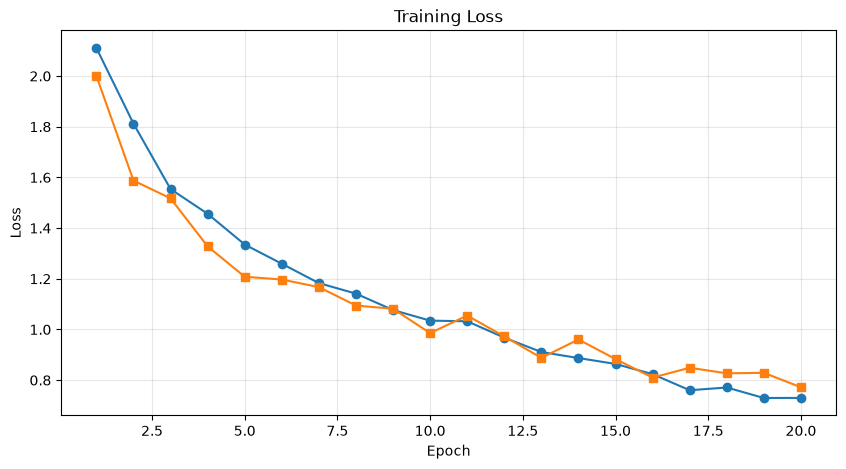


TEST ACCURACY: 70.2665%

CM : [[ 50   1   3   2   5   1   6   0   1]
 [  0  45   0   0   4   0   7   0   6]
 [  5   0  39   3   8   0   7   1   0]
 [  2   1   1  76  15   3  18   2   0]
 [  2   2   1   4  52   2   8   2   2]
 [ 11   0   1   3   3  49   8   0   0]
 [  5   2   4   4  13   0 110   0   0]
 [  2   0   0   3  12   4   4  23   0]
 [  2   2   0   1   3   0   0   0  57]]


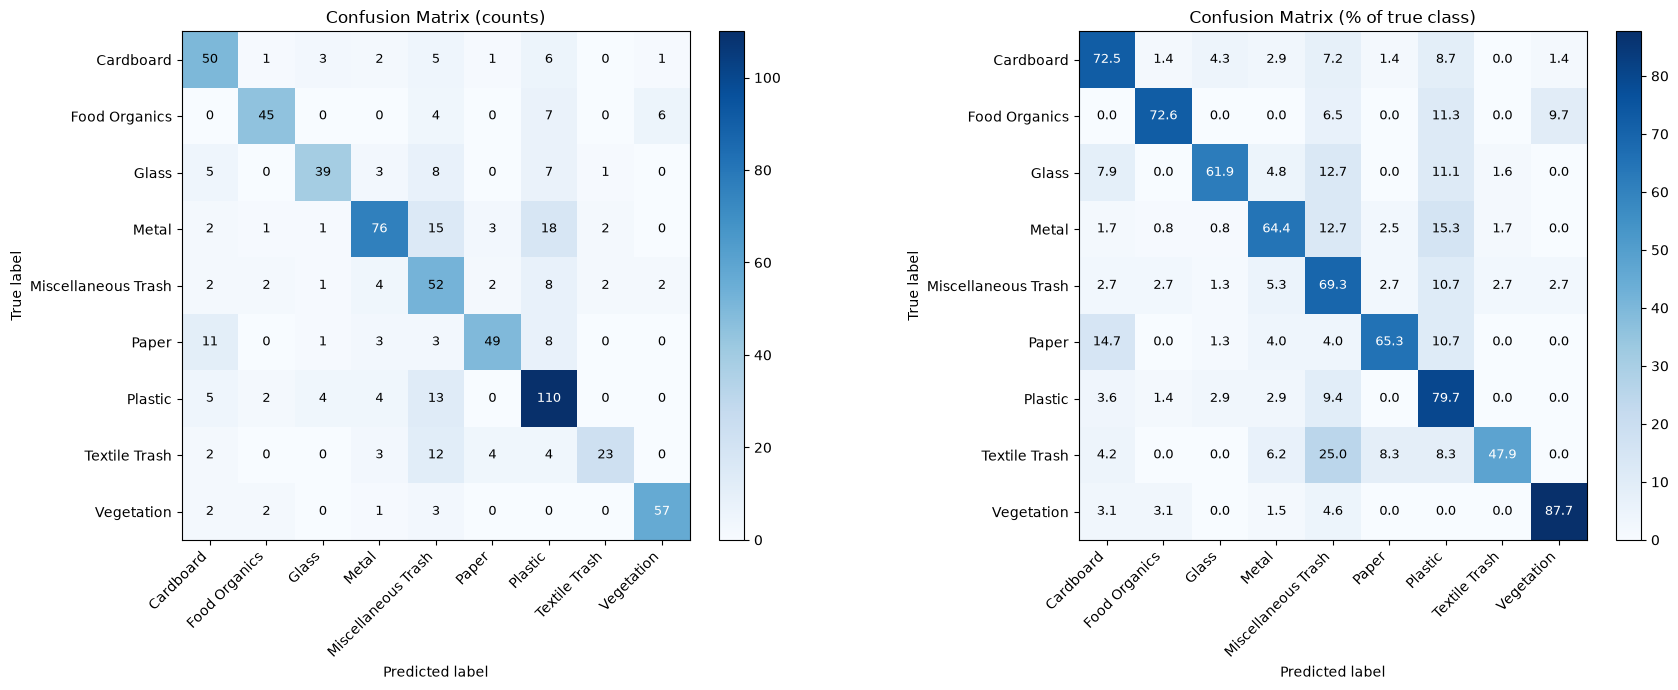


Precision: 0.7321%

Recall: 0.7027%


In [50]:
import time 

model = WasteImageNN()

start_time = time.perf_counter()
train_loss, validation_loss = train(model=model, train_loader=train_loader, val_loader=val_loader, num_ephohs=20, lr=1e-3)
end_time = time.perf_counter()
print(f"Traing Time: {end_time-start_time}")
# plot
plot_training_loss(train_losses=train_loss, validation_losses=validation_loss)
test_acc = evaluate_test(model=model, test_loader=test_loader)

In [51]:
# save model 
torch.save(model.state_dict(), Path("../models/model_A.pth"))

Depth-wise Separable covolutions

In [52]:
import torch.nn as nn 

class DepthwiseSeparableConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()

        # depthwise 
        self.depthwise = nn.Sequential(
            nn.Conv2d(
                in_channels,
                in_channels,
                kernel_size=3,
                stride=1,
                padding=1,
                groups=in_channels,
                bias=False
            ),
            nn.BatchNorm2d(in_channels),
            nn.ReLU(inplace=True)
        )

        # pointwise
        self.pointwise = nn.Sequential(
            nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=1,
                stride=1,
                padding=0,
                bias=False
            ),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self,x):
        x = self.depthwise(x)
        x = self.pointwise(x)
        return x

In [53]:
# CNN - Depth wise separable : 100k parameters
class WasteImageNNLight(nn.Module):
    def __init__(self, num_classes=9, hidden=206):
        super().__init__()

        # features 
        self.features = nn.Sequential(
            # 3 -> 32
            DepthwiseSeparableConv(3,32),
            nn.MaxPool2d(2), # --> 32*32*32

            # 32 -> 64
            DepthwiseSeparableConv(32,64),
            nn.MaxPool2d(2), # --> 64*16*16

            # 64 -> 128
            DepthwiseSeparableConv(64, 128),
            nn.MaxPool2d(2), # --> 128*8*8

            # # 128 -> 256
            # DepthwiseSeparableConv(128, 256),
            # nn.MaxPool2d(2) # --> 256*4*4
        )

        
        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),  # adaptive avg pooling before flattern
            nn.Flatten(),
            nn.Dropout(0.3),
            nn.Linear(128, 256), # parameter reduction | parameters = input*hidden + hidden
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            nn.Linear(256, num_classes)
        )
    def forward(self, x):
        return self.classifier(self.features(x))

In [54]:
model_light = WasteImageNNLight().to(device)
print(model_light)
total_params = sum(p.numel() for p in model_light.parameters())
print(f"Total parameters: {total_params:,}")

WasteImageNNLight(
  (features): Sequential(
    (0): DepthwiseSeparableConv(
      (depthwise): Sequential(
        (0): Conv2d(3, 3, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=3, bias=False)
        (1): BatchNorm2d(3, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (2): ReLU(inplace=True)
      )
      (pointwise): Sequential(
        (0): Conv2d(3, 32, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (2): ReLU(inplace=True)
      )
    )
    (1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (2): DepthwiseSeparableConv(
      (depthwise): Sequential(
        (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
        (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (2): ReLU(inplace=True)
      )


Using the device : cuda

Training for 20 epoches...



Epoch [1/20] | Train Loss: 2.0118 |  Validation Loss : 1.8259
Epoch [2/20] | Train Loss: 1.7425 |  Validation Loss : 1.5684
Epoch [3/20] | Train Loss: 1.5841 |  Validation Loss : 1.5289
Epoch [4/20] | Train Loss: 1.4729 |  Validation Loss : 1.4663
Epoch [5/20] | Train Loss: 1.4359 |  Validation Loss : 1.3221
Epoch [6/20] | Train Loss: 1.3590 |  Validation Loss : 1.2309
Epoch [7/20] | Train Loss: 1.3194 |  Validation Loss : 1.1866
Epoch [8/20] | Train Loss: 1.2574 |  Validation Loss : 1.1950
Epoch [9/20] | Train Loss: 1.2389 |  Validation Loss : 1.2246
Epoch [10/20] | Train Loss: 1.2013 |  Validation Loss : 1.1311
Epoch [11/20] | Train Loss: 1.1905 |  Validation Loss : 1.1248
Epoch [12/20] | Train Loss: 1.1590 |  Validation Loss : 1.1574
Epoch [13/20] | Train Loss: 1.1540 |  Validation Loss : 1.0932
Epoch [14/20] | Train Loss: 1.1109 |  Validation Loss : 1.1073
Epoch [15/20] | Train Loss: 1.0888 |  Validation Loss : 1.1091
Epoch [16/20] | Train Loss: 1.0785 |  Validation Loss : 1.0002
E

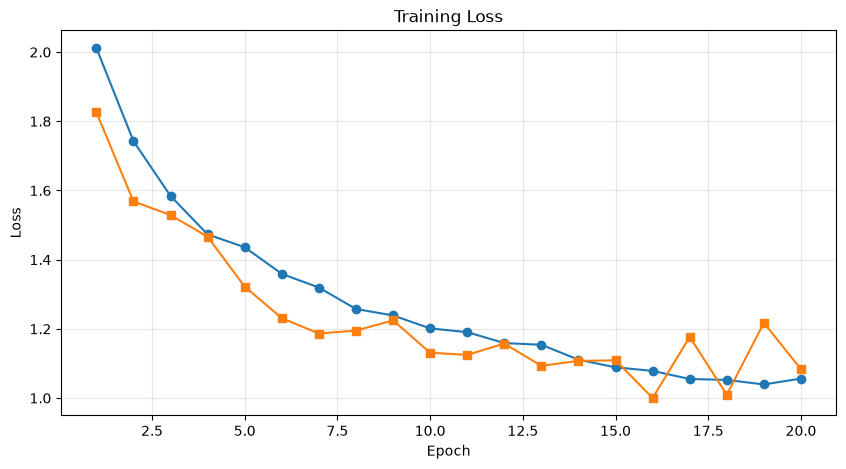


TEST ACCURACY: 61.4306%

CM : [[ 51   2   4   7   1   2   1   0   1]
 [  0  57   0   2   0   0   1   0   2]
 [  0   1  33  21   3   0   5   0   0]
 [  1   3   0 106   1   2   4   1   0]
 [  0  11   0  29  20   3   7   1   4]
 [  9   0   5  14   2  39   6   0   0]
 [  0   5   2  43   6   2  77   3   0]
 [  0   3   0  17  11   6   2   7   2]
 [  0  17   0   0   0   0   0   0  48]]


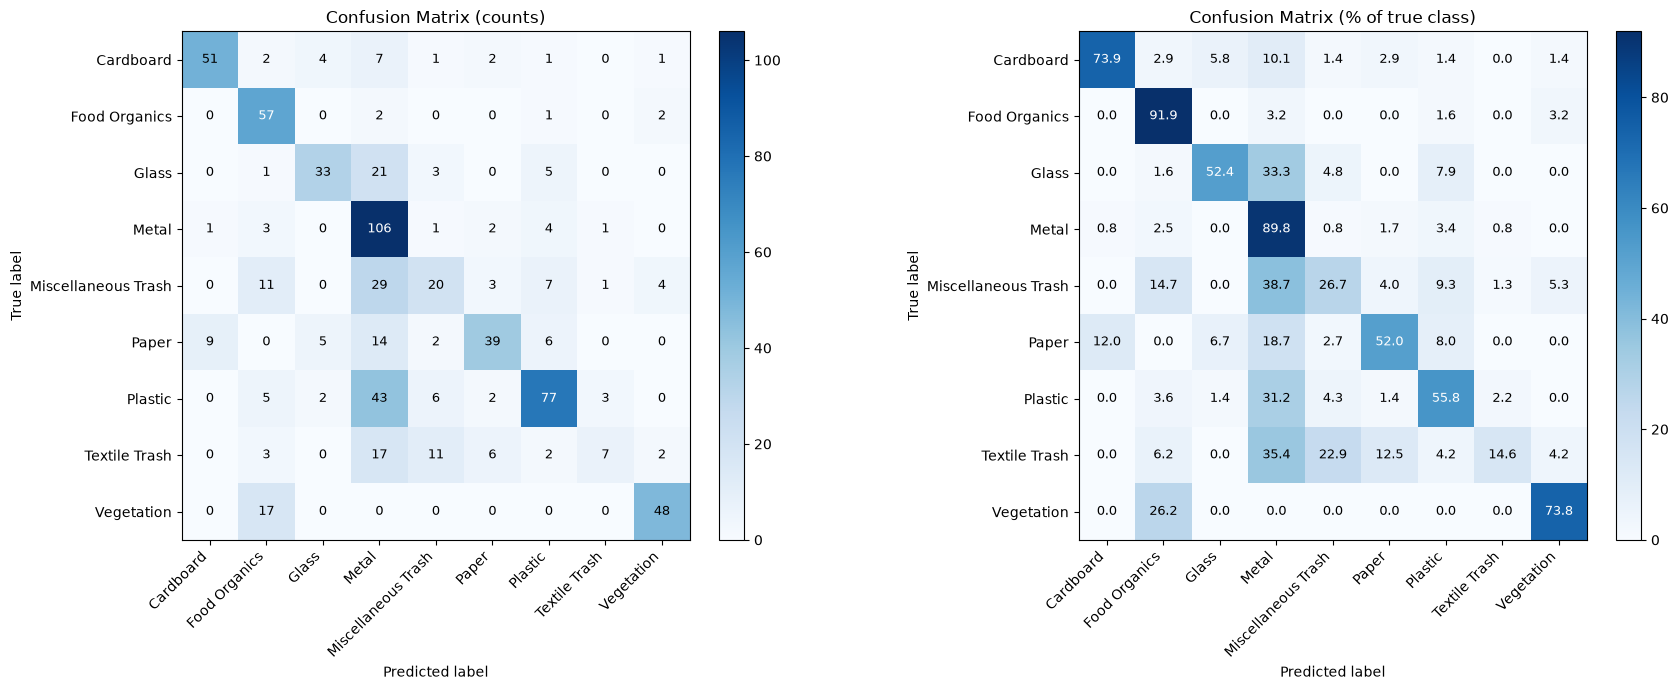


Precision: 0.6552%

Recall: 0.6143%


In [55]:
import time

start_time = time.perf_counter()
train_loss, validation_loss = train(model=model_light, train_loader=train_loader, val_loader=val_loader, num_ephohs=20, lr=1e-3)
end_time = time.perf_counter()
print(f"Training Time : {end_time-start_time}")
# plot and results 
plot_training_loss(train_losses=train_loss, validation_losses=validation_loss)
test_results = evaluate_test(model=model_light, test_loader=test_loader)

In [56]:
torch.save(model_light.state_dict(), Path("../models/model_B.pth"))